In [6]:
import numpy as np 
from matplotlib.colors import SymLogNorm
import matplotlib.pyplot as plt

In [7]:
zeus_masks = 'data/video2024-02-20T21_16_26__223e__0-59996.mgz'

# Electrical field computation for empty tank and dipole source fish

In [3]:
# Imagine 1000 x 1000 grid of tank (living in [0,1] x [0,1])

Ngrid = 5
h = 1.0 / (Ngrid - 1)                      # nodes at i*h, i = 0..N-1, covering [0,1]

# size of fish (head v tail opposite sources distance)

l = 1/6 # wrt side of square tank

rng = np.random.default_rng(0)
source_loc = rng.uniform(0, 1, size=2)        # + pole (head), uniform over the tank

# pick an orientation whose – pole also lands inside the tank
while True:
    theta = rng.uniform(0, 2*np.pi)
    sink_loc = source_loc + l * np.array([np.cos(theta), np.sin(theta)])
    if (sink_loc >= 0).all() and (sink_loc <= 1).all():
        break


# current (constant at the moment)
I = 1

b = np.zeros((Ngrid, Ngrid))



def place_current_on_grid(b, x, y, I):
    """Inject current I at (x, y) onto its <=4 surrounding nodes (bilinear).
       Off-grid neighbours at the far edge/corner are skipped automatically."""
    fi, fj = x / h, y / h
    i, j   = int(fi), int(fj)          # cell index (= floor, since x, y >= 0)
    a, c   = fi - i, fj - j            # fractional position inside the cell
    for di, wx in ((0, 1 - a), (1, a)):
        for dj, wy in ((0, 1 - c), (1, c)):
            ii, jj = i + di, j + dj
            if 0 <= ii < Ngrid and 0 <= jj < Ngrid:
                b[ii, jj] += I * wx * wy

def place_current_on_grid(b, x, y, I, h, N):
    fi, fj = x/h, y/h; i, j = int(fi), int(fj); a, c = fi-i, fj-j
    for di, wx in ((0, 1-a), (1, a)):
        for dj, wy in ((0, 1-c), (1, c)):
            ii, jj = i+di, j+dj
            if 0 <= ii < N and 0 <= jj < N:
                b[ii, jj] += I * wx * wy


# place_current_on_grid(b, source_loc[0], source_loc[1], I=I, h, N) # positive current bcs source
# place_current_on_grid(b, sink_loc[0], sink_loc[1], I=-I,) # negative current bcs sink


In [4]:
# import scipy.sparse as sp

# def laplacian_2d_neumann(N):
#     """N^2 x N^2 sparse 5-point Laplacian on an NxN grid (C-order / .ravel()),
#        with zero-flux walls: diag = -(# real neighbours) -> interior -4,
#        edge -3, corner -2; +1 for each existing neighbour."""
#     e    = np.ones(N)
#     main = -2*e.copy(); main[0] = -1; main[-1] = -1        # Neumann (no-flux) ends
#     D1   = sp.diags([e[:-1], main, e[:-1]], [-1, 0, 1])    # 1D second difference
#     I    = sp.identity(N)
#     return (sp.kron(D1, I) + sp.kron(I, D1)).tocsr()       # 2D Kronecker sum

# laplacian_2d = laplacian_2d_neumann(N=3)
# print(laplacian_2d)

In [5]:
def idx(i, j, N):           # grid point (i, j)  ->  position in the flat vector
    return i * N + j        # row-major / C order

def to_vector(phi):         # (N, N) grid   ->  (N*N,) vector
    return phi.ravel()

def to_grid(v, N):          # (N*N,) vector ->  (N, N) grid
    return v.reshape(N, N)

import scipy.sparse as sp
def build_A(N):
    rows, cols, vals = [], [], []
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N)
            deg = 0
            for di, dj in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                ii, jj = i + di, j + dj
                if 0 <= ii < N and 0 <= jj < N:        # neighbour exists
                    rows.append(k); cols.append(idx(ii, jj, N)); vals.append(1.0)
                    deg += 1                            # count it
            rows.append(k); cols.append(k); vals.append(-float(deg))   # -(# neighbours)
    return sp.coo_matrix((vals, (rows, cols)), shape=(N*N, N*N)).tocsr()

def compute_E(phi, h):
    dphidx, dphidy = np.gradient(phi, h)   # phi axis0 = x, axis1 = y
    Ex, Ey = -dphidx, -dphidy              # E = -grad(phi)
    return Ex, Ey, np.hypot(Ex, Ey)        # Ex, Ey, |E|

A = build_A(Ngrid)
print(A)

  (0, 0)	-2.0
  (0, 1)	1.0
  (0, 5)	1.0
  (1, 0)	1.0
  (1, 1)	-3.0
  (1, 2)	1.0
  (1, 6)	1.0
  (2, 1)	1.0
  (2, 2)	-3.0
  (2, 3)	1.0
  (2, 7)	1.0
  (3, 2)	1.0
  (3, 3)	-3.0
  (3, 4)	1.0
  (3, 8)	1.0
  (4, 3)	1.0
  (4, 4)	-2.0
  (4, 9)	1.0
  (5, 0)	1.0
  (5, 5)	-3.0
  (5, 6)	1.0
  (5, 10)	1.0
  (6, 1)	1.0
  (6, 5)	1.0
  (6, 6)	-4.0
  :	:
  (18, 18)	-4.0
  (18, 19)	1.0
  (18, 23)	1.0
  (19, 14)	1.0
  (19, 18)	1.0
  (19, 19)	-3.0
  (19, 24)	1.0
  (20, 15)	1.0
  (20, 20)	-2.0
  (20, 21)	1.0
  (21, 16)	1.0
  (21, 20)	1.0
  (21, 21)	-3.0
  (21, 22)	1.0
  (22, 17)	1.0
  (22, 21)	1.0
  (22, 22)	-3.0
  (22, 23)	1.0
  (23, 18)	1.0
  (23, 22)	1.0
  (23, 23)	-3.0
  (23, 24)	1.0
  (24, 19)	1.0
  (24, 23)	1.0
  (24, 24)	-2.0


In [6]:
# use conjugate gradient to solve 
from scipy.sparse.linalg import cg
# def solve_potential(A, b, maxiter=20000):
#     """Solve A phi = b for the singular Neumann system via CG on (-A) phi = -b."""
#     rhs = -(b.ravel())
#     it = [0]
#     cb = lambda xk: it.__setitem__(0, it[0] + 1)
#     kw = dict(maxiter=maxiter, callback=cb)
#     phi, info = cg(-A, rhs, **kw)
#     phi = -phi.mean()                                   # fix the constant (gauge)
#     return phi, info, it[0]

def solve_potential(A, b, maxiter=20000, tol=1e-8):
    """Solve -∇²φ = s  (physical Poisson) via CG on the SPD operator (-A)."""
    rhs = b.ravel()                          # <-- was -(b.ravel());  drop the minus
    it = [0]; cb = lambda xk: it.__setitem__(0, it[0] + 1)
    kw = dict(maxiter=maxiter, callback=cb)
    # if "rtol" in inspect.signature(cg).parameters:
    #     kw.update(rtol=tol, atol=0.0)
    # else:
    #     kw.update(tol=tol)
    phi, info = cg(-A, rhs, **kw)            # (-A) is SPD; solves (-A)φ = b  ⟺ -∇²φ = s
    phi -= phi.mean()
    return phi, info, it[0]

In [7]:
# ---------------- plotting ----------------
def plot_potential(phi, source, sink, N, path):
    g = np.linspace(0, 1, N)
    fig, ax = plt.subplots(figsize=(6, 5))
    # first axis is x -> transpose so x is horizontal; origin lower so y points up
    im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r")
    ax.contour(g, g, phi.T, levels=16, colors="k", linewidths=0.4, alpha=0.45)
    ax.plot(*source, "o", mfc="#C0392B", mec="k", ms=8, label="+ source (head)")
    ax.plot(*sink,   "s", mfc="#2C6FBB", mec="k", ms=8, label="- sink (tail)")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(f"electric potential  φ   (N = {N})")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    ax.set_xticks([0,1],[0,1])

    grid_x_locations = np.arange(0, 1, step=h)
    grid_y_locations = np.arange(0, 1, step=h)
    # 3. Draw independent vertical and horizontal grid lines
    for gx in grid_x_locations:
        ax.axvline(x=gx, color='gray', linestyle='-', linewidth=0.7, alpha=0.5)

    for gy in grid_y_locations:
        ax.axhline(y=gy, color='gray', linestyle='-', linewidth=0.7, alpha=0.5)


    plt.colorbar(im, ax=ax, fraction=0.046, label="φ")
    plt.tight_layout(); plt.savefig(path, dpi=130)

    

In [8]:
def sample_fish(rng, l):
    s = rng.uniform(0, 1, size=2)
    while True:
        th = rng.uniform(0, 2*np.pi)
        k = s + l*np.array([np.cos(th), np.sin(th)])
        if (k >= 0).all() and (k <= 1).all():
            return s, k


In [9]:
def plot_potential(phi, source, sink, N, path, Ex=None, Ey=None):
    g = np.linspace(0, 1, N)
    fig, ax = plt.subplots(figsize=(6, 5))

    # # --- CHANGE 1: clip the color range -> stronger colors (lower % = punchier) ---
    # vmax = np.percentile(np.abs(phi), 95)
    # im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r",
    #                vmin=-vmax, vmax=vmax)                       # add vmin/vmax

    # ax.contour(g, g, phi.T, levels=16, colors="k", linewidths=0.4, alpha=0.45)

    # --- smooth decay: nonlinear norm instead of a hard linear clip ---
    vmax = np.percentile(np.abs(phi), 99.5)
    norm = SymLogNorm(linthresh=vmax*0.2, linscale=1.0, vmin=-vmax, vmax=vmax)
    im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", norm=norm)

    # --- CHANGE 2: a few E-field lines on top ---
    if Ex is not None:
        ax.streamplot(g, g, Ex.T, Ey.T, color="black", density=0.7,   # density low = few lines
                      linewidth=0.8, arrowsize=0.8)

    ax.plot(*source, "o", mfc="#C0392B", mec="k", ms=8, label="+ source (head)")
    ax.plot(*sink,   "s", mfc="#2C6FBB", mec="k", ms=8, label="- sink (tail)")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(f"electric potential  φ   (N = {N})")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    ax.set_xticks([0, 1], [0, 1])

    grid_x_locations = np.arange(0, 1, step=h)
    grid_y_locations = np.arange(0, 1, step=h)
    for gx in grid_x_locations:
        ax.axvline(x=gx, color='gray', linestyle='-', linewidth=0.7, alpha=0.5)
    for gy in grid_y_locations:
        ax.axhline(y=gy, color='gray', linestyle='-', linewidth=0.7, alpha=0.5)

    plt.colorbar(im, ax=ax, fraction=0.046, label="φ")
    plt.tight_layout(); plt.savefig(path, dpi=130)

dphidx, dphidy = np.gradient(phi, h)
Ex, Ey = -dphidx, -dphidy
plot_potential(phi, source_loc, sink_loc, N, "potential.png", Ex=Ex, Ey=Ey)

NameError: name 'phi' is not defined

In [13]:
def multipole_sources(tail, head, n, I0=1.0):
    """Thesis EOD model (constant current): n+1 point currents along the fish midline.
       'tail' and 'head' are the two furthest points (the body endpoints, length L apart).
       Points are placed uniformly: r_i = tail + (i/n)(head - tail), i = 0..n.
       Magnitudes m_0 = -1 (tail sink), m_i = 1/n (the n body sources) -> sum = 0.
       Returns positions (n+1, 2) and currents I_i = m_i * I0."""
    tail, head = np.asarray(tail, float), np.asarray(head, float)
    i = np.arange(n + 1)
    positions = tail + np.outer(i / n, head - tail)      # uniform tail -> head
    m = np.full(n + 1, 1.0 / n); m[0] = -1.0             # one sink, n sources
    return positions, m * I0                              # constant amplitude (no f(t))


def build_multipole_b(positions, currents, h, N):
    """Set the environment's current density (the RHS b) from all point currents.
       Each is deposited bilinearly onto its <=4 grid nodes; net current forced to 0."""
    b = np.zeros((N, N))
    for (x, y), Ii in zip(positions, currents):
        place_current_on_grid(b, x, y, Ii, h, N)
    b -= b.mean()                                         # enforce sum(b) = 0 exactly
    return b

import os

def plot_multipole(phi, positions, currents, N, path=None, Ex=None, Ey=None, norm=None):
    g = np.linspace(0, 1, N)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    if norm is None:
        vmax = np.percentile(np.abs(phi), 99.99)
        norm = SymLogNorm(linthresh=vmax*0.03, linscale=1.0, vmin=-vmax, vmax=vmax)
    im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", norm=norm)
    if Ex is not None:
        ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.5, arrowsize=0.6)
    ax.plot(positions[:, 0], positions[:, 1], "-", color="0.2", lw=1)
    src, snk = currents > 0, currents < 0
    # 2C6FBB
    ax.scatter(*positions[src].T, c="#C0392B", s=22, ec="k", lw=0.4, zorder=5, label="+ body sources")
    ax.scatter(*positions[snk].T, marker="s", c="#2C6FBB", s=45, ec="k", lw=0.6, zorder=5, label="- tail sink")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
    plt.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    if path:                                    # save only if you ask for it
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        plt.savefig(path, dpi=130, bbox_inches="tight", pad_inches=0.03)
    plt.show()                                  # <-- this is what actually displays it

In [10]:
def plot_waveform_on_fish(positions, phi):

    N = phi.shape[0]
    body_pos_grid = (positions * N).astype(int)
    
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(positions.shape[0]),phi[tuple(body_pos_grid.T)])

In [11]:
N = 500; h = 1.0/(N-1); I0 = 1; n = 101        # n+1 = 9 point currents
L = 1/5                                          # fish length (tail-to-head)

rng = np.random.default_rng(0)
tail, head = sample_fish(rng, L)                 # the two furthest points (endpoints)
positions, currents = multipole_sources(tail, head, n, I0)
b = build_multipole_b(positions, currents, h, N)

A = build_A(N)
phi = to_grid(solve_potential(A, b)[0], N)
dphidx, dphidy = np.gradient(phi, h); Ex, Ey = -dphidx, -dphidy
plot_multipole(phi, positions, currents, N, "data/multipole.png", Ex=Ex, Ey=Ey)

plot_waveform_on_fish(positions, phi)


NameError: name 'multipole_sources' is not defined

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

def phi_along_segment(phi, tail, head, h, n_samples=300):
    """Sample phi along the tail->head midline. Returns arc-length s and phi(s)."""
    ts = np.linspace(0, 1, n_samples)
    pts = tail + np.outer(ts, head - tail)          # (n_samples, 2) points in [0,1]
    fi, fj = pts[:, 0]/h, pts[:, 1]/h               # -> grid coordinates (first axis = x)
    vals = map_coordinates(phi, [fi, fj], order=1)  # bilinear sample (matches deposition)
    s = ts * np.linalg.norm(head - tail)            # arc length from tail, in tank units
    return s, vals, pts

s, phi_line, pts = phi_along_segment(phi, tail, head, h)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# left: phi along the body
ax1.plot(s, phi_line, "-", color="0.2")
ax1.axhline(0, color="0.7", lw=0.6)
ax1.scatter(np.linalg.norm(positions - tail, axis=1),      # the actual source points
            map_coordinates(phi, [positions[:,0]/h, positions[:,1]/h], order=1),
            c=np.where(currents > 0, "#C0392B", "#2C6FBB"), s=25, ec="k", lw=0.4, zorder=5)
ax1.set_xlabel("distance along body (tail → head)"); ax1.set_ylabel(r"$\varphi$")
ax1.set_title("potential along the fish midline")

plt.tight_layout(); plt.show()

NameError: name 'phi' is not defined

In [ ]:
print("sum b:", b.sum())                    # should be ~0 (net current zero)
print("tail current:", currents[0])         # should be NEGATIVE (-I0): the sink
print("body currents:", currents[1:4])      # should be POSITIVE (+I0/n): the sources
# and check the solve preserved sign:
print("phi at head vs tail:", phi_grid[tuple(head_ij)], phi_grid[tuple(tail_ij)])

In [13]:
positions, currents = multipole_sources(tail, head, n, I0)
print("tail current  :", currents[0])       # MUST be negative (sink)
print("body currents :", currents[1:4])     # MUST be positive (sources)

b = build_multipole_b(positions, currents, h, N)
print("b min/max     :", b.min(), b.max())  # tail cell negative, body cells positive
print("b sum         :", b.sum())           # ~0

tail current  : -1.0
body currents : [0.00990099 0.00990099 0.00990099]
b min/max     : -0.507391166364612 0.024161253299352477
b sum         : 0.0


In [12]:
import os

# ---- settings ----
N = 200; h = 1.0/(N-1)
L  = 0.2            # fish length (tail-to-head, the two extreme poles)
n  = 101             # n+1 point currents along the body
I0 = 1.0
n_seeds = 12       # how many random fish to generate
vmax = 0.4         # fixed shared color scale across all plots
SHARED_NORM = SymLogNorm(linthresh=vmax*0.03, linscale=1.0, vmin=-vmax, vmax=vmax)

os.makedirs("data", exist_ok=True)
A = build_A(N)                                   # geometry fixed -> build once

for seed in range(n_seeds):
    rng = np.random.default_rng(seed)            # one seed = one random pole placement
    tail, head = sample_fish(rng, L)             # the two extreme poles
    positions, currents = multipole_sources(tail, head, n, I0)
    b = build_multipole_b(positions, currents, h, N)

    phi = to_grid(solve_potential(A, b)[0], N)
    dphidx, dphidy = np.gradient(phi, h); Ex, Ey = -dphidx, -dphidy

    plot_multipole(phi, positions, currents, N,
                   path=f"data/multipole_seed{seed:02d}.png",
                   Ex=Ex, Ey=Ey, norm=SHARED_NORM)     # same norm -> comparable
    print(f"seed {seed:02d}: tail={tail.round(2)} head={head.round(2)} -> saved")

ValueError: cannot reshape array of size 1 into shape (200,200)

In [ ]:
# how long does it take on CPU per image generation (as fct of discretization)
# think about size of data -> many days; goal of efficiency

In [15]:
def build_A_mask(fish_mask, N, sigma_water=1.0, sigma_fish=5.0):
    """Build A from a boolean fish mask instead of a sigma array.
       fish_mask: (N, N) bool/0-1 array — True where fish, False where water.
       Edges carry the harmonic-mean face conductivity; walls handled as before."""
    sigma = np.where(fish_mask, sigma_fish, sigma_water)      # 0/1 mask -> conductivity field

    rows, cols, vals = [], [], []
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N)
            wsum = 0.0
            for di, dj in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                ii, jj = i + di, j + dj
                if 0 <= ii < N and 0 <= jj < N:               # neighbour exists (walls: skip)
                    sa, sb = sigma[i, j], sigma[ii, jj]
                    w = 2.0*sa*sb / (sa + sb)                 # harmonic mean = face conductivity
                    rows.append(k); cols.append(idx(ii, jj, N)); vals.append(w)
                    wsum += w
            rows.append(k); cols.append(k); vals.append(-wsum)
    return sp.coo_matrix((vals, (rows, cols)), shape=(N*N, N*N)).tocsr()

# Electric field with other fish 

In [13]:
from scipy.ndimage import zoom

def fish_axis(mask):
    """Return the two endpoints of the mask's principal axis, in [0,1] tank coords."""
    ys, xs = np.nonzero(mask)
    pts = np.column_stack([xs, ys]).astype(float)
    c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]     # principal direction
    t = (pts - c) @ v
    p0, p1 = c + t.min()*v, c + t.max()*v
    H, W = mask.shape
    to_tank = lambda p: np.array([p[0]/(W-1), p[1]/(H-1)])    # pixels -> [0,1]
    return to_tank(p0), to_tank(p1)                            # WHICH is tail? see below

def sigma_from_masks(masks, N, sigma_water=1.0, sigma_fish=5.0, include_source_body=True, source_oid=0):
    """masks: {oid: (900,900) bool}. Returns (sigma, mask_grids) both on the NxN tank grid."""
    sigma = np.full((N, N), sigma_water)
    mask_grids = {}
    for oid, m in masks.items():
        if not m.any():
            continue                                   # fish absent this frame
        mg = mask_to_grid(m, N)                        # 900x900 -> NxN boolean
        mask_grids[oid] = mg
        if oid == source_oid and not include_source_body:
            continue                                   # source fish stays "invisible" to sigma
        sigma[mg] = sigma_fish
    return sigma, mask_grids

def sigma_with_fish(mask_grid, sigma_water=1.0, sigma_fish=5.0):
    """Conductivity field: water everywhere, higher-sigma inside the fish body."""
    sigma = np.full(mask_grid.shape, sigma_water)
    sigma[mask_grid] = sigma_fish          # sigma_fish > sigma_water = more conductive
    return sigma

def mask_to_grid(mask, N):
    """900x900 boolean -> NxN boolean on the [0,1] tank grid (nearest-neighbor)."""
    z = zoom(mask.astype(float), N / mask.shape[0], order=0)   # order=0 = nearest, stays binary
    return z[:N, :N] > 0.5

In [14]:
def sigma_from_stack(masks, N, sigma_water=1.0, sigma_fish=5.0, skip=None):
    """masks: (n_fish, P, P) boolean stack. Returns (N, N) conductivity field.
       skip: optional fish index to leave out of sigma (e.g. the source fish)."""
    sigma = np.full((N, N), float(sigma_water))
    for f, m in enumerate(masks):                 # iterate over the fish axis
        if skip is not None and f == skip:
            continue
        if not m.any():
            continue                              # fish absent this frame
        sigma[mask_to_grid(m, N)] = sigma_fish
    return sigma


def build_A_sigma(masks, N, sigma_water=1.0, sigma_fish=5.0, skip=None):
    """Neumann Laplacian weighted by conductivity, from an (n_fish, P, P) mask stack.
       Edge weight = harmonic mean of the two cells' sigma (the face conductivity);
       diagonal = -(sum of incident face weights). Off-grid neighbours (tank walls)
       are skipped -> zero-flux, exactly as in build_A."""
    sigma = sigma_from_stack(masks, N, sigma_water, sigma_fish, skip)

    rows, cols, vals = [], [], []
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N)
            wsum = 0.0
            for di, dj in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                ii, jj = i + di, j + dj
                if 0 <= ii < N and 0 <= jj < N:                # wall: skip (sigma_outside = 0)
                    sa, sb = sigma[i, j], sigma[ii, jj]
                    w = 2.0*sa*sb / (sa + sb)                  # harmonic mean face conductivity
                    rows.append(k); cols.append(idx(ii, jj, N)); vals.append(w)
                    wsum += w
            rows.append(k); cols.append(k); vals.append(-wsum)
    return sp.coo_matrix((vals, (rows, cols)), shape=(N*N, N*N)).tocsr(), sigma

In [15]:
def plot_multipole(phi, positions, currents, N, path=None, Ex=None, Ey=None, norm=None,
                   mask_grids=None, source_oid=0):
    g = np.linspace(0, 1, N)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    if norm is None:
        vmax = np.percentile(np.abs(phi), 99.99)
        norm = SymLogNorm(linthresh=vmax*0.03, linscale=1.0, vmin=-vmax, vmax=vmax)
    im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", norm=norm)
    if Ex is not None:
        ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.5, arrowsize=0.6)

    # ---- NEW: outline every fish body ----
    if mask_grids:
        for oid, mg in mask_grids.items():
            is_src = (oid == source_oid)
            ax.contourf(g, g, mg.T.astype(float), levels=[0.5, 1.5],
                        colors=["0.35"], alpha=0.18, zorder=3)                 # filled body
            ax.contour(g, g, mg.T.astype(float), levels=[0.5], zorder=4,
                       colors=["#FFD400" if is_src else "#00C000"],
                       linewidths=1.8 if is_src else 1.2)                      # outline
        # legend proxies
        from matplotlib.lines import Line2D
        ax.plot([], [], color="#FFD400", lw=1.8, label=f"fish {source_oid} (source)")
        ax.plot([], [], color="#00C000", lw=1.2, label="other fish (conductive)")

    ax.plot(positions[:, 0], positions[:, 1], "-", color="0.2", lw=1, zorder=5)
    src, snk = currents > 0, currents < 0
    ax.scatter(*positions[src].T, c="#C0392B", s=22, ec="k", lw=0.4, zorder=6, label="+ body sources")
    ax.scatter(*positions[snk].T, marker="s", c="#2C6FBB", s=45, ec="k", lw=0.6, zorder=6, label="- tail sink")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
    plt.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    if path:
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        plt.savefig(path, dpi=130, bbox_inches="tight", pad_inches=0.03)
    plt.show()

In [16]:
mask_example_3_frames = np.load('data/mask_example_3_frames.npy')

fish_mask = mask_example_3_frames[0] # frame 0
print(fish_mask.shape)

(4, 912, 912)


In [17]:
import numpy as np

tail, head = fish_axis_from_mask(fish_mask[0])          # fish 0 = the emitter
positions, currents = multipole_sources(tail, head, n, I0)

def fish_axis_from_mask(mask, tank_shape=None):
    """Mask (P,P) bool -> (tail, head) endpoints in [0,1] tank coords.
       Long axis from PCA; tail = the narrower end (electric organ side)."""
    ys, xs = np.nonzero(mask)
    pts = np.column_stack([xs, ys]).astype(float)      # (n, 2) as (x, y)
    c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]   # principal direction (unit)

    t = (pts - c) @ v                                  # coordinate along the axis
    p_lo, p_hi = c + t.min()*v, c + t.max()*v          # the two extreme tips

    # --- which tip is the tail? the tail end is thinner ---
    w = (pts - c) @ np.array([-v[1], v[0]])            # perpendicular coordinate (width)
    L = t.max() - t.min()
    near_lo = np.abs(t - t.min()) < 0.25*L             # pixels in the first quarter
    near_hi = np.abs(t - t.max()) < 0.25*L             # pixels in the last quarter
    width_lo = w[near_lo].std() if near_lo.any() else np.inf
    width_hi = w[near_hi].std() if near_hi.any() else np.inf
    tail_px, head_px = (p_lo, p_hi) if width_lo < width_hi else (p_hi, p_lo)

    H, W = mask.shape
    to_tank = lambda p: np.array([p[0]/(W-1), p[1]/(H-1)])   # pixels -> [0,1]
    return to_tank(tail_px), to_tank(head_px)


In [18]:
def sigma_from_stack(masks, N, sigma_water=1.0, sigma_fish=5.0, skip=None):
    if isinstance(masks, dict):
        masks = np.stack([masks[k] for k in sorted(masks)])
    masks = np.asarray(masks)
    if masks.ndim == 2:                     # single (P,P) -> stack of one
        masks = masks[None, ...]
    assert masks.ndim == 3, f"expected (n_fish, P, P), got {masks.shape}"
    print("sigma_from_stack got:", masks.shape)      # temporary: confirms what arrives

    sigma = np.full((N, N), float(sigma_water))
    for f, m in enumerate(masks):
        if skip is not None and f == skip:
            continue
        if not m.any():
            continue
        sigma[mask_to_grid(m, N)] = sigma_fish
    return sigma

In [21]:
N = 400; h = 1.0/(N-1)

sigma_fish = 100 # 10-100 times more conductive than water

tail, head = fish_axis_from_mask(fish_mask[0])          # fish 0 = the emitter
positions, currents = multipole_sources(tail, head, n, I0)

A, sigma = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=sigma_fish, skip=0)   # all 4 bodies in sigma
# or, if fish 0 should be a bare point source in uniform water:
# A, sigma = build_A_sigma(masks_stack, N, skip=0)

b   = build_multipole_b(positions, currents, h, N)    # fish 0's EOD
phi = to_grid(solve_potential(A, b)[0], N)

dphidx, dphidy = np.gradient(phi, h); Ex, Ey = -dphidx, -dphidy

sigma_from_stack got: (4, 912, 912)


In [23]:
print("sigma unique:", np.unique(sigma))                 # must show [1., 5.]
print("fish cells in sigma:", (sigma != 1.0).sum(), "of", N*N)
print("A off-diagonal weights:", np.unique(np.round(A.data, 3))[:8])   # expect 1.0, ~1.667, 5.0

sigma unique: [  1. 100.]
fish cells in sigma: 1886 of 160000
A off-diagonal weights: [-400.    -301.98  -203.96  -105.941   -6.941   -5.96    -4.98    -4.   ]


In [24]:
# sigma, mask_grids = sigma_from_masks(fish_mask, N, sigma_water=1.0, sigma_fish=5.0)

# # fish 0's tail/head -> multipole source (get these from its mask, see note below)
# tail, head = fish_axis(fish_mask[0])                              # your endpoint extraction
# positions, currents = multipole_sources(tail, head, n=8, I0=1.0)
# b = build_multipole_b(positions, currents, h, N)

# A   = build_A_sigma(sigma, N)                                 # all 4 bodies baked in
# phi = to_grid(solve_potential(A, b)[0], N)

In [23]:
def plot_multipole(ax, phi, positions, currents, N, path=None, Ex=None, Ey=None, norm=None,
                   masks=None, source_oid=0):
    g = np.linspace(0, 1, N)
    if norm is None:
        vmax = np.percentile(np.abs(phi), 99.99)
        norm = SymLogNorm(linthresh=vmax*0.03, linscale=1.0, vmin=-vmax, vmax=vmax)
    im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", norm=norm)
    if Ex is not None:
        ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.5, arrowsize=0.6)

    if masks is not None:
        for oid, m in enumerate(masks):        # (4, 916, 916)
            if oid == source_oid:              # <-- source fish: multipole only, no contour
                continue
            if not m.any():
                continue
            mg = mask_to_grid(m, N).astype(float)
            ax.contourf(g, g, mg.T, levels=[0.5, 1.5], colors=["0.35"], alpha=0.2, zorder=3)
            ax.contour(g, g, mg.T, levels=[0.5], colors=["#00C000"], linewidths=1.4, zorder=4)
        ax.plot([], [], color="#00C000", lw=1.4, label="other fish (conductive)")

    ax.plot(positions[:, 0], positions[:, 1], "-", color="0.2", lw=1, zorder=5)
    src, snk = currents > 0, currents < 0
    ax.scatter(*positions[src].T, c="#C0392B", s=22, ec="k", lw=0.4, zorder=6, label="+ body sources")
    ax.scatter(*positions[snk].T, marker="s", c="#2C6FBB", s=45, ec="k", lw=0.6, zorder=6, label="- tail sink")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
    plt.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    if path:
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        plt.savefig(path, dpi=130, bbox_inches="tight", pad_inches=0.03)
    # plt.show()

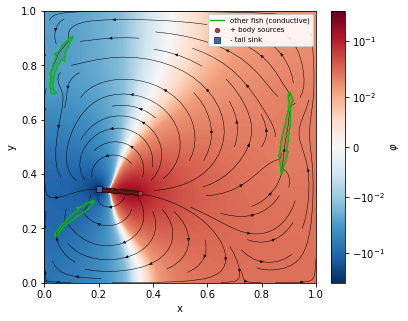

In [111]:
plot_multipole(phi, positions, currents, N, Ex=Ex, Ey=Ey,
               masks=fish_mask, source_oid=0)      # fish_mask: (4, 916, 916)
# g = np.linspace(0, 1, N)
# ax.contour(g, g, mask_grid.T.astype(float), levels=[0.5], colors="lime", linewidths=1.5)

In [122]:
A_water, _ = build_A_sigma(fish_mask, N, sigma_fish=1, skip=0)   # uniform water (no bodies)
A_fish,  s = build_A_sigma(fish_mask, N, sigma_fish=sigma_fish, skip=0)   # with bodies

phi_water = to_grid(solve_potential(A_water, b)[0], N)
phi_fish  = to_grid(solve_potential(A_fish,  b)[0], N)
dphi = phi_fish - phi_water                                         # the electric image

# plt.imshow(dphi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r",
#            vmin=-np.percentile(np.abs(dphi), 99), vmax=np.percentile(np.abs(dphi), 99))
# # overlay the fish so you can see the blobs sit on them
# for f, m in enumerate(fish_mask):
#     if f == 0 or not m.any(): continue
#     plt.contour(np.linspace(0,1,N), np.linspace(0,1,N), mask_to_grid(m,N).T.astype(float),
#                 levels=[0.5], colors="lime", linewidths=1)
# plt.colorbar(); plt.show()

# print("perturbation max:", np.abs(dphi).max(), "vs field max:", np.abs(phi_fish).max())
# # plt.imshow(dphi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r"); plt.colorbar(); plt.show()

sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)


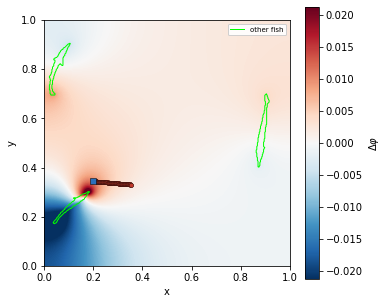

In [121]:
g = np.linspace(0, 1, N)
fig, ax = plt.subplots(figsize=(5.5, 5))

v = np.percentile(np.abs(dphi), 99)
im = ax.imshow(dphi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-v, vmax=v)

for f, m in enumerate(fish_mask):
    if not m.any():
        continue
    mg = mask_to_grid(m, N).T.astype(float)
    is_src = (f == 0)
    if is_src == False:
        ax.contour(g, g, mg, levels=[0.5], zorder=4,
                colors=["#FFD400" if is_src else "lime"],          # source = yellow
                linewidths=1.8 if is_src else 1.0,
                linestyles="--" if is_src else "-")                 # dashed = not in sigma

# the source fish's multipole points
ax.plot(positions[:, 0], positions[:, 1], "-", color="0.2", lw=1, zorder=5)
src, snk = currents > 0, currents < 0
ax.scatter(*positions[src].T, c="#C0392B", s=18, ec="k", lw=0.3, zorder=6)
ax.scatter(*positions[snk].T, marker="s", c="#2C6FBB", s=40, ec="k", lw=0.5, zorder=6)

# legend proxies
# ax.plot([], [], color="#FFD400", lw=1.8, ls="--", label="fish 0 (source, not in σ)")
ax.plot([], [], color="lime", lw=1.0, label="other fish")

fig.colorbar(im, ax=ax, label=r"$\Delta\varphi$")
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

In [ ]:
# compare to ground truth EOD from electrodes 
# speed things up
# introduce permittivity 
# communication vs perceiving

In [113]:
_, sw = build_A_sigma(fish_mask, N, sigma_fish=1.0, skip=0)
_, sf = build_A_sigma(fish_mask, N, sigma_fish=5.0, skip=0)
print("water sigma unique:", np.unique(sw))     # must be [1.]  <- only this
print("fish  sigma unique:", np.unique(sf))     # must be [1., 5.]
print("cells differing:", (sw != sf).sum())     # = the 3 non-source fish cells

sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
water sigma unique: [1.]
fish  sigma unique: [1. 5.]
cells differing: 1886


In [70]:
out = solve_potential(A, b)
print(type(out), len(out) if isinstance(out, tuple) else np.shape(out))

<class 'tuple'> 3


In [73]:
N = 200; h = 1.0/(N-1)

A, sigma = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=5.0, skip=0)  # skip source fish
b = build_multipole_b(positions, currents, h, N)

res = solve_potential(A, b)
phi_vec = res[0] if isinstance(res, tuple) else res       # tolerate either signature
phi = to_grid(phi_vec, N)

dphidx, dphidy = np.gradient(phi, h); Ex, Ey = -dphidx, -dphidy
assert phi.shape == Ex.shape == (N, N), (phi.shape, Ex.shape)   # catches drift immediately

sigma_from_stack got: (4, 912, 912)


In [30]:
print(fish_mask.shape)

(4, 912, 912)


sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)


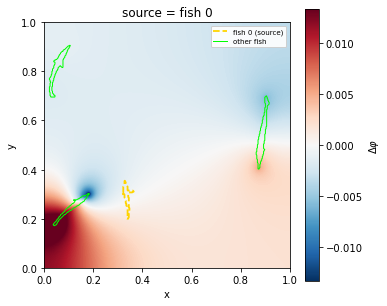

sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)


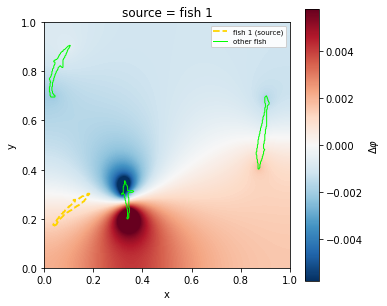

sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)


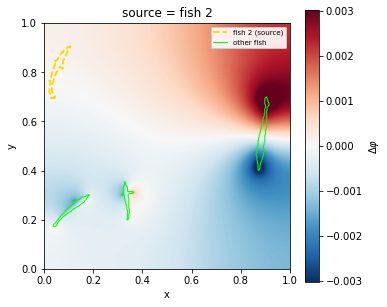

sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)


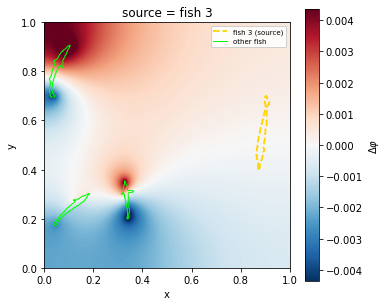

In [36]:
for source_fish in [0, 1, 2, 3]:
    tail, head = fish_axis_from_mask(fish_mask[source_fish])
    positions, currents = multipole_sources(tail, head, n, I0)
    b = build_multipole_b(positions, currents, h, N)

    A_water, _ = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=1.0,        skip=source_fish)
    A_fish,  _ = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=sigma_fish, skip=source_fish)
    phi_water = to_grid(solve_potential(A_water, b)[0], N)
    phi_fish  = to_grid(solve_potential(A_fish,  b)[0], N)
    dphi = phi_fish - phi_water

    g = np.linspace(0, 1, N)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    v = np.percentile(np.abs(dphi), 99)
    im = ax.imshow(dphi.T, origin="lower", extent=[0,1,0,1], cmap="RdBu_r", vmin=-v, vmax=v)

    for f, m in enumerate(fish_mask):
        if not m.any():
            continue
        mg = mask_to_grid(m, N).T.astype(float)
        is_src = (f == source_fish)
        ax.contour(g, g, mg, levels=[0.5], zorder=4,
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0,
                   linestyles="--" if is_src else "-")          # source dashed yellow, others solid green

    # ax.plot(positions[:, 0], positions[:, 1], "-", color="0.2", lw=1, zorder=5)
    # srcp, snkp = currents > 0, currents < 0
    # ax.scatter(*positions[srcp].T, c="#C0392B", s=18, ec="k", lw=0.3, zorder=6)
    # ax.scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=40, ec="k", lw=0.5, zorder=6)

    ax.plot([], [], color="#FFD400", lw=1.8, ls="--", label=f"fish {source_fish} (source)")
    ax.plot([], [], color="lime", lw=1.0, label="other fish")
    fig.colorbar(im, ax=ax, label=r"$\Delta\varphi$")
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
    ax.set_title(f"source = fish {source_fish}")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    plt.show()

In [26]:
tail, head = fish_axis_from_mask(fish_mask[source_fish])
print("endpoint (should be inside yellow blob):", tail, head)

mg = mask_to_grid(fish_mask[source_fish], N)      # NOT transposed
ii, jj = np.nonzero(mg)
print("mask centroid in [0,1]:", ii.mean()/(N-1), jj.mean()/(N-1))

endpoint (should be inside yellow blob): [0.69851371 0.90988085] [0.40113419 0.87020094]
mask centroid in [0,1]: 0.8881808540263187 0.53749622282657


In [31]:
mask_example_3_frames = np.load('data/mask_example_3_frames.npy')

fish_mask = mask_example_3_frames[0] # frame 0
print(fish_mask.shape)

(4, 912, 912)


sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
shared color limit ± 0.0084475731573561


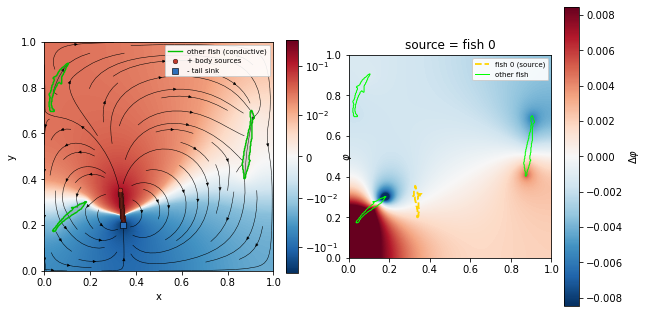

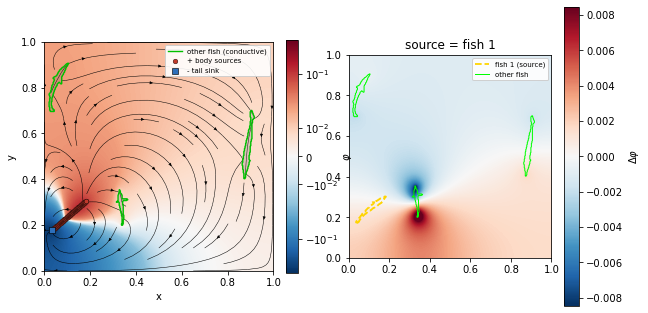

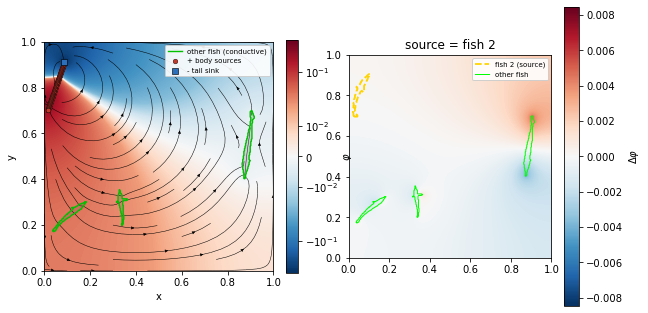

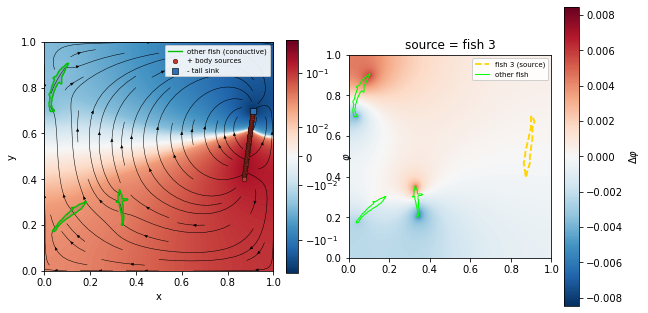

In [32]:
# ---- pass 1: compute every dphi, find one shared color limit ----
results = {}
for source_fish in [0, 1, 2, 3]:
    tail, head = fish_axis_from_mask(fish_mask[source_fish])
    positions, currents = multipole_sources(tail, head, n, I0)
    b = build_multipole_b(positions, currents, h, N)
    A_water, _ = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=1.0,        skip=source_fish)
    A_fish,  _ = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=sigma_fish, skip=source_fish)
    phi_water = to_grid(solve_potential(A_water, b)[0], N)
    phi_fish  = to_grid(solve_potential(A_fish,  b)[0], N)
    results[source_fish] = (phi_fish, phi_fish - phi_water, positions, currents)

v = np.percentile(np.abs(np.array([d for _, d, _, _ in results.values()])), 99)   # ONE limit for all
print("shared color limit ±", v)

# ---- pass 2: plot all four with the same vmin/vmax ----
g = np.linspace(0, 1, N)
for source_fish, (phi, dphi, positions, currents) in results.items():
    fig, ax = plt.subplots(1,2, figsize=(10, 5.5))

    dphidx, dphidy = np.gradient(phi, h); Ex, Ey = -dphidx, -dphidy

    plot_multipole(ax[0], phi, positions, currents, N, Ex=Ex, Ey=Ey,
               masks=fish_mask, source_oid=source_fish) 

    im = ax[1].imshow(dphi.T, origin="lower", extent=[0,1,0,1],
                   cmap="RdBu_r", vmin=-v, vmax=v)                 # <-- shared scale

    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        mg = mask_to_grid(m, N).T.astype(float)
        is_src = (f == source_fish)
        ax[1].contour(g, g, mg, levels=[0.5], zorder=4,
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0,
                   linestyles="--" if is_src else "-")

    # ax.plot(positions[:,0], positions[:,1], "-", color="0.2", lw=1, zorder=5)
    # srcp, snkp = currents > 0, currents < 0
    # ax.scatter(*positions[srcp].T, c="#C0392B", s=18, ec="k", lw=0.3, zorder=6)
    # ax.scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=40, ec="k", lw=0.5, zorder=6)
    ax[1].plot([], [], color="#FFD400", lw=1.8, ls="--", label=f"fish {source_fish} (source)")
    ax[1].plot([], [], color="lime", lw=1.0, label="other fish")
    fig.colorbar(im, ax=ax[1], label=r"$\Delta\varphi$")
    ax[1].set_xlim(0,1); ax[1].set_ylim(0,1); ax[1].set_aspect("equal")
    ax[1].set_title(f"source = fish {source_fish}")
    ax[1].legend(loc="upper right", fontsize=7, framealpha=0.9)
    plt.show()

In [27]:
tail, head = fish_axis_from_mask(fish_mask[source_fish])
m = mask_to_grid(fish_mask[source_fish], N)
xi, yi = np.nonzero(m)
print("centroid:", xi.mean()/(N-1), yi.mean()/(N-1))
print("tail:", tail, " head:", head)     # both should bracket the centroid

centroid: 0.8881808540263187 0.53749622282657
tail: [0.69851371 0.90988085]  head: [0.40113419 0.87020094]


In [29]:
def fish_axis_from_mask(mask):
    """mask first axis = x, second = y  (SAME convention as build_A_sigma / deposition)."""
    xs, ys = np.nonzero(mask)                     # <-- first index is x here, not y
    pts = np.column_stack([xs, ys]).astype(float) # (n, 2) as (x, y)
    c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]
    t = (pts - c) @ v
    p_lo, p_hi = c + t.min()*v, c + t.max()*v
    P0, P1 = mask.shape                           # (nx, ny)
    to_tank = lambda p: np.array([p[0]/(P0-1), p[1]/(P1-1)])
    return to_tank(p_lo), to_tank(p_hi)           # (fix tail/head disambiguation separately)

sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
sigma_from_stack got: (4, 912, 912)
shared color limit ± 0.0084475731573561


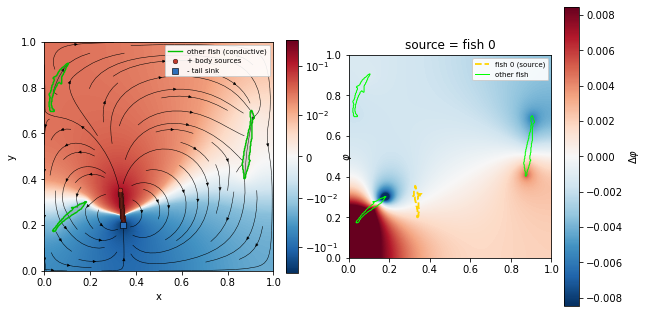

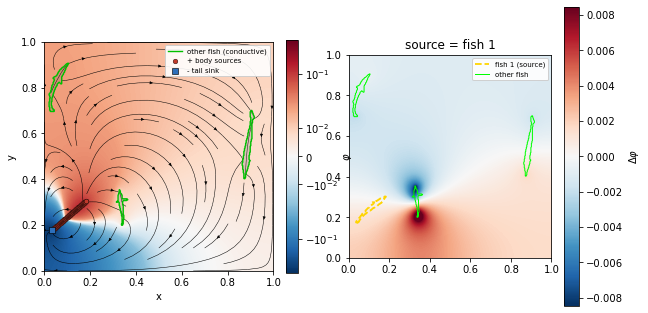

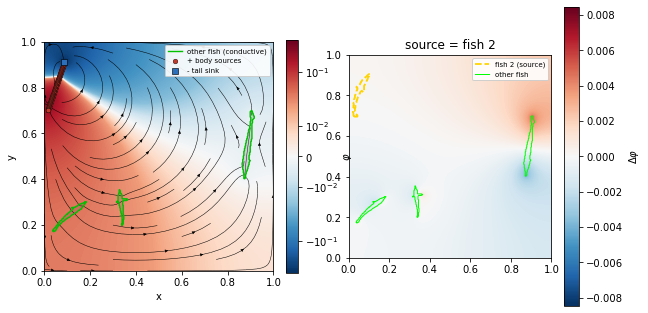

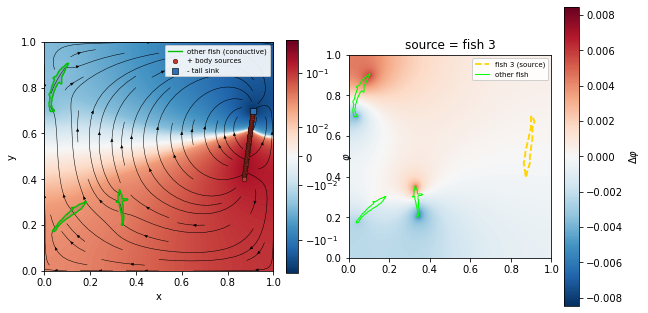

In [30]:
# ---- pass 1: compute every dphi, find one shared color limit ----
results = {}
for source_fish in [0, 1, 2, 3]:
    tail, head = fish_axis_from_mask(fish_mask[source_fish])
    positions, currents = multipole_sources(tail, head, n, I0)
    b = build_multipole_b(positions, currents, h, N)
    A_water, _ = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=1.0,        skip=source_fish)
    A_fish,  _ = build_A_sigma(fish_mask, N, sigma_water=1.0, sigma_fish=sigma_fish, skip=source_fish)
    phi_water = to_grid(solve_potential(A_water, b)[0], N)
    phi_fish  = to_grid(solve_potential(A_fish,  b)[0], N)
    results[source_fish] = (phi_fish, phi_fish - phi_water, positions, currents)

v = np.percentile(np.abs(np.array([d for _, d, _, _ in results.values()])), 99)   # ONE limit for all
print("shared color limit ±", v)

# ---- pass 2: plot all four with the same vmin/vmax ----
g = np.linspace(0, 1, N)
for source_fish, (phi, dphi, positions, currents) in results.items():
    fig, ax = plt.subplots(1,2, figsize=(10, 5.5))

    dphidx, dphidy = np.gradient(phi, h); Ex, Ey = -dphidx, -dphidy

    plot_multipole(ax[0], phi, positions, currents, N, Ex=Ex, Ey=Ey,
               masks=fish_mask, source_oid=source_fish) 

    im = ax[1].imshow(dphi.T, origin="lower", extent=[0,1,0,1],
                   cmap="RdBu_r", vmin=-v, vmax=v)                 # <-- shared scale

    for f, m in enumerate(fish_mask):
        if not m.any(): continue
        mg = mask_to_grid(m, N).T.astype(float)
        is_src = (f == source_fish)
        ax[1].contour(g, g, mg, levels=[0.5], zorder=4,
                   colors=["#FFD400" if is_src else "lime"],
                   linewidths=1.8 if is_src else 1.0,
                   linestyles="--" if is_src else "-")

    # ax.plot(positions[:,0], positions[:,1], "-", color="0.2", lw=1, zorder=5)
    # srcp, snkp = currents > 0, currents < 0
    # ax.scatter(*positions[srcp].T, c="#C0392B", s=18, ec="k", lw=0.3, zorder=6)
    # ax.scatter(*positions[snkp].T, marker="s", c="#2C6FBB", s=40, ec="k", lw=0.5, zorder=6)
    ax[1].plot([], [], color="#FFD400", lw=1.8, ls="--", label=f"fish {source_fish} (source)")
    ax[1].plot([], [], color="lime", lw=1.0, label="other fish")
    fig.colorbar(im, ax=ax[1], label=r"$\Delta\varphi$")
    ax[1].set_xlim(0,1); ax[1].set_ylim(0,1); ax[1].set_aspect("equal")
    ax[1].set_title(f"source = fish {source_fish}")
    ax[1].legend(loc="upper right", fontsize=7, framealpha=0.9)
    plt.show()

# General electric field model: resistance and capacitance of other fish

In [8]:
from scipy.ndimage import zoom

def occupancy_field(masks, N, skip=None):
    """Fish masks (dict or stack of PxP bool) -> smooth NxN occupancy in [0,1].
       order=1 (linear) keeps fractional values at edges so the 0.5-contour
       is the physical fish boundary. occ>0.5 = inside a fish."""
    if isinstance(masks, dict):
        masks = [masks[k] for k in sorted(masks)]
    occ = np.zeros((N, N))
    for f, m in enumerate(masks):
        if (skip is not None and f == skip) or not np.any(m):
            continue
        P = m.shape[0]
        occ = np.maximum(occ, zoom(m.astype(float), N / P, order=1)[:N, :N])
    return occ

In [9]:
def theta_matrices(occ, level=0.5):
    """From the occupancy field, the crossing fraction on every grid edge.
       Returns theta_x[i,j] for edge (i,j)->(i+1,j)   shape (N-1, N)
               theta_y[i,j] for edge (i,j)->(i,j+1)   shape (N, N-1)
       theta = fraction of the edge (from the first node) at which occ crosses `level`.
       Uncut edges (both nodes same side) are stored as 0.5 (value irrelevant there)."""
    def cross(a, b):                                   # a, b = occ at the two nodes
        cut = (a - level) * (b - level) < 0            # do they straddle the boundary?
        d = a - b
        th = np.where(np.abs(d) > 1e-12, (a - level) / d, 0.5)
        return np.where(cut, np.clip(th, 1e-6, 1 - 1e-6), 0.5)
    theta_x = cross(occ[:-1, :], occ[1:, :])           # along +x
    theta_y = cross(occ[:, :-1], occ[:, 1:])           # along +y
    return theta_x, theta_y

In [10]:
def material_fields(occ, omega,
                    sigma_water=1.0, eps_water=0.0,
                    sigma_fish=5.0,  eps_fish=0.0):
    """Assign (sigma, eps) per node from occupancy, then gamma = sigma + i*omega*eps."""
    inside = occ > 0.5
    sigma = np.where(inside, sigma_fish, sigma_water)
    eps   = np.where(inside, eps_fish,   eps_water)
    return sigma + 1j * omega * eps                     # complex admittivity field

In [11]:
import scipy.sparse as sp

def build_A(gamma, theta_x, theta_y, N):
    """div(gamma grad phi) = -s, theta-weighted complex face admittivity.
       gamma_eff = ( theta/gamma_C + (1-theta)/gamma_M )^-1 per edge, using the
       precomputed theta_x / theta_y. Off-grid neighbour skipped -> Neumann wall."""
    rows, cols, vals = [], [], []
    def edge(k, kk, gC, gM, th):
        w = gC if gC == gM else 1.0 / (th/gC + (1.0-th)/gM)
        rows.append(k); cols.append(kk); vals.append(w)
        return w
    for i in range(N):
        for j in range(N):
            k = idx(i, j, N); wsum = 0j
            if i > 0:      wsum += edge(k, idx(i-1,j,N), gamma[i,j], gamma[i-1,j], 1-theta_x[i-1,j])
            if i < N-1:    wsum += edge(k, idx(i+1,j,N), gamma[i,j], gamma[i+1,j],   theta_x[i,  j])
            if j > 0:      wsum += edge(k, idx(i,j-1,N), gamma[i,j], gamma[i,j-1], 1-theta_y[i,j-1])
            if j < N-1:    wsum += edge(k, idx(i,j+1,N), gamma[i,j], gamma[i,j+1],   theta_y[i,  j])
            rows.append(k); cols.append(k); vals.append(-wsum)
    return sp.coo_matrix((vals, (rows, cols)), shape=(N*N, N*N), dtype=complex).tocsr()

In [12]:
from scipy.sparse.linalg import splu

def idx(i, j, N):
    return i * N + j

def solve_potential(A, b, pin=0):
    """Solve A phi = b, complex singular Neumann system. A is complex symmetric
       (not Hermitian) so CG is invalid -> LU. Pin one node for the gauge."""
    M = (-A).tolil(); rhs = -(b.ravel().astype(complex))
    M[pin, :] = 0; M[pin, pin] = 1; rhs[pin] = 0
    phi = splu(M.tocsc()).solve(rhs)
    return phi - phi.mean()

In [13]:
mask_example_3_frames = np.load('data/mask_example_3_frames.npy')

fish_mask = mask_example_3_frames[0] # frame 0
print(fish_mask.shape)

(4, 912, 912)


In [14]:
def multipole_sources(tail, head, n, I0=1.0):
    """Thesis EOD model (constant current): n+1 point currents along the fish midline.
       'tail' and 'head' are the two furthest points (the body endpoints, length L apart).
       Points are placed uniformly: r_i = tail + (i/n)(head - tail), i = 0..n.
       Magnitudes m_0 = -1 (tail sink), m_i = 1/n (the n body sources) -> sum = 0.
       Returns positions (n+1, 2) and currents I_i = m_i * I0."""
    tail, head = np.asarray(tail, float), np.asarray(head, float)
    i = np.arange(n + 1)
    positions = tail + np.outer(i / n, head - tail)      # uniform tail -> head
    m = np.full(n + 1, 1.0 / n); m[0] = -1.0             # one sink, n sources
    return positions, m * I0                              # constant amplitude (no f(t))


def build_multipole_b(positions, currents, h, N):
    """Set the environment's current density (the RHS b) from all point currents.
       Each is deposited bilinearly onto its <=4 grid nodes; net current forced to 0."""
    b = np.zeros((N, N))
    for (x, y), Ii in zip(positions, currents):
        place_current_on_grid(b, x, y, Ii, h, N)
    b -= b.mean()                                         # enforce sum(b) = 0 exactly
    return b

import os

def plot_multipole(phi, positions, currents, N, path=None, Ex=None, Ey=None, norm=None):
    g = np.linspace(0, 1, N)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    if norm is None:
        vmax = np.percentile(np.abs(phi), 99.99)
        norm = SymLogNorm(linthresh=vmax*0.03, linscale=1.0, vmin=-vmax, vmax=vmax)
    im = ax.imshow(phi.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", norm=norm)
    if Ex is not None:
        ax.streamplot(g, g, Ex.T, Ey.T, color="k", density=0.7, linewidth=0.5, arrowsize=0.6)
    ax.plot(positions[:, 0], positions[:, 1], "-", color="0.2", lw=1)
    src, snk = currents > 0, currents < 0
    # 2C6FBB
    ax.scatter(*positions[src].T, c="#C0392B", s=22, ec="k", lw=0.4, zorder=5, label="+ body sources")
    ax.scatter(*positions[snk].T, marker="s", c="#2C6FBB", s=45, ec="k", lw=0.6, zorder=5, label="- tail sink")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
    plt.colorbar(im, ax=ax, fraction=0.046, label=r"$\varphi$")
    if path:                                    # save only if you ask for it
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        plt.savefig(path, dpi=130, bbox_inches="tight", pad_inches=0.03)
    plt.show()                                  # <-- this is what actually displays it

In [15]:
import numpy as np

def fish_axis_from_mask(mask, tank_shape=None):
    """Mask (P,P) bool -> (tail, head) endpoints in [0,1] tank coords.
       Long axis from PCA; tail = the narrower end (electric organ side)."""
    ys, xs = np.nonzero(mask)
    pts = np.column_stack([xs, ys]).astype(float)      # (n, 2) as (x, y)
    c = pts.mean(0)
    v = np.linalg.svd(pts - c, full_matrices=False)[2][0]   # principal direction (unit)

    t = (pts - c) @ v                                  # coordinate along the axis
    p_lo, p_hi = c + t.min()*v, c + t.max()*v          # the two extreme tips

    # --- which tip is the tail? the tail end is thinner ---
    w = (pts - c) @ np.array([-v[1], v[0]])            # perpendicular coordinate (width)
    L = t.max() - t.min()
    near_lo = np.abs(t - t.min()) < 0.25*L             # pixels in the first quarter
    near_hi = np.abs(t - t.max()) < 0.25*L             # pixels in the last quarter
    width_lo = w[near_lo].std() if near_lo.any() else np.inf
    width_hi = w[near_hi].std() if near_hi.any() else np.inf
    tail_px, head_px = (p_lo, p_hi) if width_lo < width_hi else (p_hi, p_lo)

    H, W = mask.shape
    to_tank = lambda p: np.array([p[0]/(W-1), p[1]/(H-1)])   # pixels -> [0,1]
    return to_tank(tail_px), to_tank(head_px)


In [16]:
def multipole_sources(tail, head, n, I0=1.0):
    """Thesis EOD model (constant current): n+1 point currents along the fish midline.
       'tail' and 'head' are the two furthest points (the body endpoints, length L apart).
       Points are placed uniformly: r_i = tail + (i/n)(head - tail), i = 0..n.
       Magnitudes m_0 = -1 (tail sink), m_i = 1/n (the n body sources) -> sum = 0.
       Returns positions (n+1, 2) and currents I_i = m_i * I0."""
    tail, head = np.asarray(tail, float), np.asarray(head, float)
    i = np.arange(n + 1)
    positions = tail + np.outer(i / n, head - tail)      # uniform tail -> head
    m = np.full(n + 1, 1.0 / n); m[0] = -1.0             # one sink, n sources
    return positions, m * I0                              # constant amplitude (no f(t))


In [17]:
import pandas as pd
path_csv = 'data/Data_4fish_2024-10-23T15_18_28.csv'
eod_data  = pd.read_csv(path_csv)
# eod_data  = pd.read_csv(path_csv).iloc[:100]
# eod_data.to_csv('first_100_eods.csv', index=False)
print(eod_data.head())

   Frame      Time    chin_x_1    chin_y_1  chin_score_1   mouth_x_1  \
0      1 -0.704628  289.261841  336.091583      0.829582  301.520538   
1      1 -0.699005  289.261841  336.091583      0.829582  301.520538   
2      1 -0.685097  289.261841  336.091583      0.829582  301.520538   
3      1 -0.678293  289.261841  336.091583      0.829582  301.520538   
4      1 -0.676672  289.261841  336.091583      0.829582  301.520538   

    mouth_y_1  mouth_score_1    head_x_1    head_y_1  ...  \
0  340.401062       0.971991  328.970245  384.374146  ...   
1  340.401062       0.971991  328.970245  384.374146  ...   
2  340.401062       0.971991  328.970245  384.374146  ...   
3  340.401062       0.971991  328.970245  384.374146  ...   
4  340.401062       0.971991  328.970245  384.374146  ...   

   electrode_10_time_16  electrode_10_time_17  electrode_10_time_18  \
0              0.000649             -0.002517             -0.003167   
1             -0.000857             -0.000163             

In [18]:
def solve_eod_field(I_rec, dt, occ, tx, ty, N, b_unit, probes,
                    sigma_water=1.0, eps_water=0.0, sigma_fish=5.0, eps_fish=0.0,
                    power_keep=0.999):
    """phi(t) at probe cells, solving ONLY the frequencies that carry the EOD's power."""
    keep, om, Ihat, n_t, freqs, P = eod_frequencies(I_rec, dt, power_keep)
    pidx = [idx(i, j, N) for i, j in probes]
    phi_hat = np.zeros((len(Ihat), len(probes)), complex)
    for k in keep:                                   # e.g. 5-10 solves, not 13
        A   = build_A(material_fields(occ, om[k], sigma_water, eps_water, sigma_fish, eps_fish),
                      tx, ty, N)
        psi = solve_potential(A, b_unit)             # transfer function at this omega
        phi_hat[k] = Ihat[k] * psi[pidx]
    return np.fft.irfft(phi_hat, n=n_t, axis=0), freqs[keep]

# usage: the chosen electrode trace IS your I(t)
I_rec = E[best]                                       # electrode #10, row 0
phi_t, solved_freqs = solve_eod_field(I_rec, 1/20000, occ, tx, ty, N, b_unit, skin,
                                      sigma_fish=5.0, eps_fish=2e-4)

NameError: name 'E' is not defined

In [22]:
N = 200; h = 1.0/(N-1); omega = 2*np.pi*3000.0

tail, head = fish_axis_from_mask(fish_mask[0])          # fish 0 = the emitter
positions, currents = multipole_sources(tail, head, N, I0)

occ              = occupancy_field(fish_mask, N, skip=0)          # geometry -> level-set
theta_x, theta_y = theta_matrices(occ)                            # thetas, computed ONCE, stored
gamma            = material_fields(occ, omega, sigma_water=1.0, sigma_fish=5.0,
                                              eps_water=0.0,     eps_fish=2.6e-5)
A                = build_A(gamma, theta_x, theta_y, N)
b                = build_multipole_b(positions, currents, h, N)
phi              = to_grid(solve_potential(A, b), N)              # complex field

NameError: name 'I0' is not defined

# Comparing to ground truth EODs